# GPU trial stability in Phases A and B

Compare repeated GPU measurements for the same framework and executed settings, then inspect nearby numeric settings. Phases A and B are analyzed separately because their models and workloads differ.

This notebook reads saved logs and SQLite trials; it launches no GPU benchmarks. Install the checkout with `pip install -e ".[notebook]"` first.

**What can be established:** identical-settings repeat ranges, sample standard deviation, coefficient of variation, and deviations from each group's median. Nearby settings also show parameter effects, so their differences do not establish GPU noise. Small repeat counts and incomplete environment metadata limit conclusions about stability.


In [1]:
from pathlib import Path
import json

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/llm_optimizer").is_dir())
RUN_DIRS = sorted({
    p.parent for p in (ROOT / "experiment_results").glob("*/*-measured.jsonl")
})
# For one run only: RUN_DIRS = [ROOT / "experiment_results" / "optuna-phase-b-v1"]
# Add other saved run directories here; identical paths are read only once.
PHASES = ["A", "B"]
FRAMEWORKS = ["vllm", "sglang", "trtllm"]
MIN_REPEATS = 2             # Two points establish a range, not a reliable noise distribution.
DEVIATION_ALERT_PCT = 10.0  # Descriptive alert, not a statistical significance test.
MAX_NUMERIC_CHANGES = 1
INCLUDE_UNMATCHED = False   # Default: require a COMPLETE trial matched to a log record.
EXCLUDE_DUPLICATE_RECORDS = True  # Identical full JSON records may be copied artifacts.
TOP_N = 12
SAVE_REPORT = True
REPORT_DIR = ROOT / "experiment_results" / "phase_stability_analysis"


## Comparison rules

A comparison holds phase, framework, model, full client workload (including request count, seed, and concurrency), request fingerprints, and recorded environment metadata fixed. It can span samplers and objectives, since these do not change an already selected engine configuration.

Actual native server arguments define exact matches. JSON-valued flags are decoded. TRT-LLM YAML configs are resolved from the saved run and compared by contents, so moved file paths do not create false differences. Missing flags are not assumed equivalent to explicit flags, and graph capture arrays remain part of the configuration.

Below, similar means **at most one changed numeric setting** by default. Every other setting, including booleans, attention backends, scheduler policies, and graph capture settings, must match. Edit the absolute tolerances to suit the experiment.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from llm_optimizer.experiment.stability import (
    DEFAULT_TOLERANCES, METRICS, load_measurements, eligible_records,
    exact_repeat_summary, similar_parameter_pairs,
)

NUMERIC_TOLERANCES = dict(DEFAULT_TOLERANCES)
# Examples: NUMERIC_TOLERANCES["max_batch_size"] = 8
#           NUMERIC_TOLERANCES["free_gpu_memory_fraction"] = 0.05
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)
NUMERIC_TOLERANCES


{'max_num_seqs': 8,
 'max_running_requests': 8,
 'max_batch_size': 8,
 'max_num_batched_tokens': 2048,
 'chunked_prefill_size': 2048,
 'max_num_tokens': 2048,
 'max_prefill_tokens': 2048,
 'gpu_memory_utilization': 0.05,
 'mem_fraction_static': 0.05,
 'free_gpu_memory_fraction': 0.05,
 'schedule_conservativeness': 0.25}

In [3]:
audit = load_measurements(RUN_DIRS)
selected, excluded = eligible_records(
    audit["records"], include_unmatched=INCLUDE_UNMATCHED,
    exclude_duplicate_records=EXCLUDE_DUPLICATE_RECORDS,
)
selected = [r for r in selected if r["phase"] in PHASES and r["framework"] in FRAMEWORKS]
exact = exact_repeat_summary(selected, min_repeats=MIN_REPEATS, alert_pct=DEVIATION_ALERT_PCT)
neighbors = similar_parameter_pairs(
    selected, tolerances=NUMERIC_TOLERANCES, max_changes=MAX_NUMERIC_CHANGES,
)

OBSERVATION_COLUMNS = [
    "observation_id", "phase", "framework", "concurrency", "study_name", "trial_number",
    "trial_state", "target", "sampler", "datetime_start", "datetime_complete",
    "context_id", "config_id", "exact_group_id", "source_file", "source_line",
    "measurement_valid", "server_config", "client_args", "identity_warnings", "exclusion_reason",
]
def observation_frame(rows):
    return pd.DataFrame([
        {**{k: r.get(k) for k in OBSERVATION_COLUMNS},
         **{k: r["metrics"].get(k) for k in (*METRICS, "completed", "total_requests", "failed")}}
        for r in rows
    ], columns=OBSERVATION_COLUMNS + list(METRICS) + ["completed", "total_requests", "failed"])

observations = observation_frame(selected)
excluded_observations = observation_frame(excluded)
trials = pd.DataFrame(audit["trials"], columns=[
    "run_dir", "phase", "framework", "concurrency", "study_name", "trial_number",
    "trial_state", "sampler", "target", "failure_reason", "datetime_start", "datetime_complete",
])
groups = pd.DataFrame(exact["groups"])
repeat_metrics = pd.DataFrame(exact["metrics"])
deviations = pd.DataFrame(exact["deviations"])
neighbor_pairs = pd.DataFrame(neighbors)

print(f"Loaded {len(audit['records'])} measurement records and {len(trials)} SQLite trials.")
print(f"Analyzing {len(observations)} valid matched measurements; {len(excluded)} excluded records.")
print("SQLite adds identity and failure coverage; it is not counted as a second measurement.")
if audit["issues"]:
    display(pd.DataFrame(audit["issues"]))
if not excluded_observations.empty:
    display(excluded_observations.groupby(["phase", "framework", "exclusion_reason"], dropna=False).size().rename("records").reset_index())


Loaded 1174 measurement records and 1553 SQLite trials.
Analyzing 1166 valid matched measurements; 8 excluded records.
SQLite adds identity and failure coverage; it is not counted as a second measurement.


,phase,framework,exclusion_reason,records
0,A,trtllm,Trial state UNMATCHED,1
1,A,vllm,"Invalid metrics, incomplete requests, or changed request budget",3
2,B,sglang,"Invalid metrics, incomplete requests, or changed request budget",3
3,B,trtllm,"Invalid metrics, incomplete requests, or changed request budget",1


## Metadata and failure coverage

Placeholder framework/CUDA/driver/model revisions and missing physical GPU identifiers are reported below. Matching recorded metadata does not establish that temperature, power limits, background load, engine defaults, or software were actually unchanged.

Failed server starts consume search trials but produce no successful measurement. Invalid/incomplete benchmarks, failed trials, ambiguous matches, and unavailable native config files are excluded from repeat statistics. Full-record duplicates are excluded by default; independently measured trials with merely similar metric values are retained.


In [4]:
warning_rows = [
    {"phase": r["phase"], "framework": r["framework"], "warning": warning,
     "observation_id": r["observation_id"]}
    for r in selected for warning in r["identity_warnings"]
]
identity_warnings = pd.DataFrame(warning_rows, columns=["phase", "framework", "warning", "observation_id"])
if not identity_warnings.empty:
    display(identity_warnings.groupby(["phase", "framework", "warning"]).size().rename("observations").reset_index())
if not trials.empty:
    display(trials.groupby(["phase", "framework", "trial_state"]).size().unstack(fill_value=0))
    failures = trials[trials["trial_state"] == "FAIL"]
    if not failures.empty:
        display(failures.groupby(["phase", "framework", "failure_reason"], dropna=False).size().rename("trials").reset_index())


,phase,framework,warning,observations
0,A,sglang,Physical GPU identity not recorded,184
1,A,sglang,cuda_version missing or placeholder,184
2,A,sglang,driver_version missing or placeholder,184
3,A,sglang,framework_version missing or placeholder,184
4,A,sglang,model_revision missing or placeholder,184
5,A,trtllm,Physical GPU identity not recorded,204
6,A,trtllm,cuda_version missing or placeholder,130
7,A,trtllm,driver_version missing or placeholder,130
8,A,trtllm,framework_version missing or placeholder,130
9,A,trtllm,model_revision missing or placeholder,204


trial_state      COMPLETE  FAIL  RUNNING  WAITING
phase framework                                  
A     sglang          184     0        0        0
      trtllm          204    27        0        0
      vllm            338   187        1        0
B     sglang          164   143        0        0
      trtllm          132    23        1        0
      vllm            144     0        1        4

,phase,framework,failure_reason,trials
0,A,trtllm,ServerNotReadyError: Server did not become ready in the allotted time.,17
1,A,trtllm,NaN,10
2,A,vllm,FileNotFoundError: [Errno 2] No such file or directory: 'vllm',184
3,A,vllm,NaN,3
4,B,sglang,BenchmarkFailure: False boolean for disable_cuda_graph needs explicit framework handling.,57
5,B,sglang,BenchmarkFailure: False booleans need a validated native disable flag.,14
6,B,sglang,ServerNotReadyError: Server did not become ready in the allotted time.,42
7,B,sglang,ValueError: Unknown native argument: cuda_graph_backend_decode,24
8,B,sglang,NaN,6
9,B,trtllm,BenchmarkFailure: Invalid or changed benchmark workload.,1


## Reading the variation measures

For each exact group and metric:

- `min` / `max`: observed run-level range.
- `spread_pct`: `100 × (max − min) / median`.
- `cv_pct`: sample standard deviation divided by mean, as a percentage.
- `max_abs_deviation_pct`: largest absolute deviation from the group median.
- `n`: number of measurements, which should always accompany a variance claim.

The alert threshold applies to individual deviations from the median. It is a descriptive flag. For latency, these are variations **between runs' p95 latency values**, not the distribution of individual request latencies. No metric is normalized to a best trial, and these ranges are not confidence intervals.


In [5]:
def phase_rows(frame, phase):
    if frame.empty:
        return frame
    return frame[(frame["phase"] == phase) & frame["framework"].isin(FRAMEWORKS)]

def show_phase(phase):
    obs = phase_rows(observations, phase)
    phase_groups = phase_rows(groups, phase)
    repeated = phase_rows(repeat_metrics, phase)
    nearby = phase_rows(neighbor_pairs, phase)
    coverage = []
    for framework in FRAMEWORKS:
        g = phase_groups[phase_groups["framework"] == framework] if not phase_groups.empty else phase_groups
        repeated_groups = g[g["n"] >= MIN_REPEATS] if not g.empty else g
        count = int((obs["framework"] == framework).sum())
        coverage.append({
            "framework": framework, "valid_measurements": count,
            "exact_configs": len(g), "repeated_configs": len(repeated_groups),
            "measurements_in_repeated_configs": int(repeated_groups["n"].sum()) if not repeated_groups.empty else 0,
            "singleton_configs": int((g["n"] == 1).sum()) if not g.empty else 0,
        })
    display(pd.DataFrame(coverage))
    t = phase_rows(trials, phase)
    if not t.empty:
        display(t.groupby(["framework", "trial_state"]).size().unstack(fill_value=0))
    if repeated.empty:
        print(f"Phase {phase}: no exact groups meet MIN_REPEATS={MIN_REPEATS}; stability is not established.")
    else:
        print("Range of observed deviations, by framework and metric:")
        population = phase_rows(deviations, phase)
        display(population.groupby(["framework", "metric"])["abs_deviation_pct"].agg(
            observations="count", median="median", p90=lambda s: s.quantile(0.90),
            p95=lambda s: s.quantile(0.95), maximum="max",
        ).reset_index())
        print("These percentiles describe saved observations; heavily repeated configs contribute more points.")
        for framework in FRAMEWORKS:
            rows = repeated[repeated["framework"] == framework]
            if rows.empty:
                print(f"{framework}: insufficient exact repeats.")
                continue
            print(f"{framework}: largest exact-settings variation (inspect repeat counts and metadata).")
            display(rows.sort_values("max_abs_deviation_pct", ascending=False)[[
                "exact_group_id", "concurrency", "metric", "n", "min", "max", "median",
                "spread_pct", "cv_pct", "max_abs_deviation_pct", "alert", "studies", "server_config",
            ]].head(TOP_N))
        fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 4))
        for ax, metric in zip(axes, METRICS):
            for framework in FRAMEWORKS:
                values = population[(population["framework"] == framework) & (population["metric"] == metric)]["deviation_pct"].dropna()
                if len(values):
                    ax.hist(values, bins=20, histtype="step", label=f"{framework} (n={len(values)})")
            ax.axvline(-DEVIATION_ALERT_PCT, color="gray", linestyle="--")
            ax.axvline(DEVIATION_ALERT_PCT, color="gray", linestyle="--")
            ax.set(title=metric, xlabel="Deviation from exact-group median (%)", ylabel="Measurements")
            if ax.get_legend_handles_labels()[0]:
                ax.legend()
        fig.suptitle(f"Phase {phase}: identical-settings deviations")
        fig.tight_layout()
        if SAVE_REPORT:
            REPORT_DIR.mkdir(parents=True, exist_ok=True)
            fig.savefig(REPORT_DIR / f"phase-{phase}-exact-deviations.png", dpi=180, bbox_inches="tight")
        plt.show()
    print("Nearby numeric settings: median differences mix parameter effects and measurement variation.")
    if nearby.empty:
        print("No pairs meet the selected numeric tolerances with other settings held fixed.")
    else:
        for framework in FRAMEWORKS:
            rows = nearby[nearby["framework"] == framework]
            if rows.empty:
                continue
            print(framework)
            display(rows.sort_values("median_gap_pct", ascending=False)[[
                "metric", "concurrency", "left_group_id", "right_group_id", "left_n", "right_n",
                "left_median", "right_median", "left_min", "left_max", "right_min", "right_max",
                "median_gap_pct", "parameter_changes",
            ]].head(TOP_N))


## Phase A

Exact repetitions and nearby-setting comparisons for the Phase A model and workloads only. Workload or environment differences create separate contexts even within this phase.


,framework,valid_measurements,exact_configs,repeated_configs,measurements_in_repeated_configs,singleton_configs
0,vllm,338,54,45,329,9
1,sglang,184,64,45,165,19
2,trtllm,204,58,36,182,22


trial_state,COMPLETE,FAIL,RUNNING
framework,,,
sglang,184,0,0
trtllm,204,27,0
vllm,338,187,1


Range of observed deviations, by framework and metric:


,framework,metric,observations,median,p90,p95,maximum
0,sglang,output_throughput,165,0.698009,5.581667,7.858479,11.828970
1,sglang,p95_e2e_latency_ms,165,0.487427,4.164894,8.789032,16.801502
2,sglang,p95_ttft_ms,165,0.508745,4.298132,8.775011,17.544380
3,trtllm,output_throughput,182,2.132660,6.222650,7.799462,18.409616
4,trtllm,p95_e2e_latency_ms,182,2.090377,6.907617,9.782917,22.653028
5,trtllm,p95_ttft_ms,182,1.924069,7.275710,10.540123,26.658162
6,vllm,output_throughput,329,1.652098,5.763865,7.197068,9.822282
7,vllm,p95_e2e_latency_ms,329,1.708464,5.896344,7.933702,14.892639
8,vllm,p95_ttft_ms,329,1.799402,6.257846,8.037297,15.519640


These percentiles describe saved observations; heavily repeated configs contribute more points.
vllm: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
58,dbc37330cb4f0d52b30a0d47015b1ec151c9133d45b87022946efb64efb1e7e5,128,p95_ttft_ms,9,5931.025314,7419.775312,6422.955695,23.178581,6.724661,15.519640,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 8, 'max_num_batched_tokens': 2048, 'gpu_memory_utilization': 0.85, 'enable_chun..."
59,dbc37330cb4f0d52b30a0d47015b1ec151c9133d45b87022946efb64efb1e7e5,128,p95_e2e_latency_ms,9,6269.464621,7822.101154,6808.183059,22.805446,6.630684,14.892639,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 8, 'max_num_batched_tokens': 2048, 'gpu_memory_utilization': 0.85, 'enable_chun..."
43,e28b1e2ad51405eada87acf13227f77674250d07cc2b7e076f1268bd10cb4be0,128,p95_ttft_ms,27,1639.420566,2042.459341,1792.699713,22.482225,5.146609,13.932039,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 6144, 'gpu_memory_utilization': 0.75, 'enable_chu..."
85,1b59b164e3ae79fe1ca2b7bb13dc066019dfc32ea02dc78f85109235d3347267,128,p95_ttft_ms,14,1671.461976,2025.719965,1778.063986,19.923804,4.903450,13.928406,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 6144, 'gpu_memory_utilization': 0.8, 'enable_chun..."
86,1b59b164e3ae79fe1ca2b7bb13dc066019dfc32ea02dc78f85109235d3347267,128,p95_e2e_latency_ms,14,2085.660418,2522.919732,2214.603908,19.744358,4.804367,13.921940,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 6144, 'gpu_memory_utilization': 0.8, 'enable_chun..."
68,b30423df3933e086f109f113c89f843cbaf258a8e2d2105e3f6f6af903eda0ed,128,p95_e2e_latency_ms,26,2007.965752,2450.800566,2181.304357,20.301377,4.602528,12.354819,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 8192, 'gpu_memory_utilization': 0.8, 'enable_chun..."
67,b30423df3933e086f109f113c89f843cbaf258a8e2d2105e3f6f6af903eda0ed,128,p95_ttft_ms,26,1577.410926,1941.089631,1735.965070,20.949656,4.934791,11.816169,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 8192, 'gpu_memory_utilization': 0.8, 'enable_chun..."
115,b3a4c7d170fd725e138b0095b3fb95be1a46133badb1b09d482d5e03d741315d,128,p95_ttft_ms,3,2344.670134,2622.063904,2358.127546,11.763306,6.406128,11.192624,True,"[A-vllm-c128-e2e-tpe_multivariate-s11-r1, A-vllm-c128-pareto_throughput-tpe-s11-r1, A-vllm-c128-...","{'max_num_seqs': 24, 'max_num_batched_tokens': 8192, 'gpu_memory_utilization': 0.85, 'enable_chu..."
44,e28b1e2ad51405eada87acf13227f77674250d07cc2b7e076f1268bd10cb4be0,128,p95_e2e_latency_ms,27,2061.378252,2482.069001,2246.117505,18.729686,4.736540,10.504860,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 6144, 'gpu_memory_utilization': 0.75, 'enable_chu..."
47,a9c345d93bd61e5f638a43954d82bcaf8cddfc139099b81a5992099ab9b3134b,128,p95_e2e_latency_ms,35,2031.455228,2430.159483,2200.152100,18.121668,3.609019,10.454158,True,"[A-vllm-c128-e2e-gp-s11-r1, A-vllm-c128-e2e-tpe-s11-r1, A-vllm-c128-e2e-tpe_multivariate-s11-r1,...","{'max_num_seqs': 32, 'max_num_batched_tokens': 8192, 'gpu_memory_utilization': 0.75, 'enable_chu..."


sglang: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
211,81dab1ca4e64547ed2daab1f25b913bb6d512452fb795cef06a8ea62b2c0a05f,128,p95_ttft_ms,3,1903.683916,2247.479367,1912.026214,17.980687,9.704127,17.544380,True,"[A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1, A-sglang-c128-e2e-tpe-s11-r1]","{'max_running_requests': 16, 'chunked_prefill_size': 8192, 'mem_fraction_static': 0.8, 'schedule..."
212,81dab1ca4e64547ed2daab1f25b913bb6d512452fb795cef06a8ea62b2c0a05f,128,p95_e2e_latency_ms,3,2123.638250,2491.073990,2132.741402,17.228331,9.317324,16.801502,True,"[A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1, A-sglang-c128-e2e-tpe-s11-r1]","{'max_running_requests': 16, 'chunked_prefill_size': 8192, 'mem_fraction_static': 0.8, 'schedule..."
202,0b810e7d7e8eaf6d418eb156876f07d7a6e36cb65c5bb51c6c53ab15d4d987f0,128,p95_ttft_ms,2,2105.715668,2953.488713,2529.602190,33.514086,23.698037,16.757043,True,"[A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1]","{'max_running_requests': 24, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'schedul..."
163,b2e6b3a54f887005a149f806bbae5e11482f57664567d857180c06556fd67c63,128,p95_ttft_ms,5,4318.759868,4961.970857,4336.173435,14.833608,6.518952,14.432020,True,"[A-sglang-c128-e2e-gp-s11-r1, A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1, A-...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.8, 'schedule_..."
164,b2e6b3a54f887005a149f806bbae5e11482f57664567d857180c06556fd67c63,128,p95_e2e_latency_ms,5,4526.309087,5194.436005,4539.938023,14.716653,6.483170,14.416452,True,"[A-sglang-c128-e2e-gp-s11-r1, A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1, A-...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.8, 'schedule_..."
203,0b810e7d7e8eaf6d418eb156876f07d7a6e36cb65c5bb51c6c53ab15d4d987f0,128,p95_e2e_latency_ms,2,2414.960219,3220.448780,2817.704499,28.586694,20.213845,14.293347,True,"[A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-random-s11-r1]","{'max_running_requests': 24, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'schedul..."
140,35674edf21723a92c27f94385ee19785635bd25d051340d7448175bdc2ec344c,128,p95_e2e_latency_ms,6,4421.712439,5106.517701,4505.290076,15.200026,5.571070,13.344926,True,"[A-sglang-c128-e2e-gp-s11-r1, A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-qmc-s11-r1, A-sgl...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'schedule..."
139,35674edf21723a92c27f94385ee19785635bd25d051340d7448175bdc2ec344c,128,p95_ttft_ms,6,4215.529669,4869.769398,4298.955467,15.218574,5.563461,13.277968,True,"[A-sglang-c128-e2e-gp-s11-r1, A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-qmc-s11-r1, A-sgl...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'schedule..."
253,7b0c0bedfec657de79612463af0e030a7e370b3d3069a9931747ba7325b7e441,128,p95_ttft_ms,3,3675.950081,4225.668449,3778.109337,14.550092,7.510079,11.846113,True,"[A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-qmc-s11-r1, A-sglang-c128-e2e-random-s11-r1]","{'max_running_requests': 32, 'chunked_prefill_size': 4096, 'mem_fraction_static': 0.7, 'schedule..."
138,35674edf21723a92c27f94385ee19785635bd25d051340d7448175bdc2ec344c,128,output_throughput,6,3275.388559,3766.895377,3714.812611,13.230999,5.077014,11.828970,True,"[A-sglang-c128-e2e-gp-s11-r1, A-sglang-c128-e2e-grid-s11-r1, A-sglang-c128-e2e-qmc-s11-r1, A-sgl...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'schedule..."


trtllm: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
271,6f833bb6d604833d850afe0dcfb354483f882d66759b198632533213e25948e6,128,p95_ttft_ms,7,1916.193778,2610.630769,2061.162682,33.691518,10.651913,26.658162,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r1, A-trtllm-c128-e2e-tpe-s11-r11, A-tr...","{'max_batch_size': 24, 'max_num_tokens': 6144, 'config': {'cuda_graph_config': {'batch_sizes': [..."
272,6f833bb6d604833d850afe0dcfb354483f882d66759b198632533213e25948e6,128,p95_e2e_latency_ms,7,2220.549765,2926.375132,2385.897176,29.583227,9.386530,22.653028,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r1, A-trtllm-c128-e2e-tpe-s11-r11, A-tr...","{'max_batch_size': 24, 'max_num_tokens': 6144, 'config': {'cuda_graph_config': {'batch_sizes': [..."
290,4816470da0f4f959f9cece69a22a9dc09d52231f26d32689baf131f9d99f07d8,128,p95_e2e_latency_ms,6,3046.502650,3945.853330,3227.943428,27.861414,10.047481,22.240473,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 24, 'max_num_tokens': 2048, 'config': {'cuda_graph_config': {'batch_sizes': [..."
289,4816470da0f4f959f9cece69a22a9dc09d52231f26d32689baf131f9d99f07d8,128,p95_ttft_ms,6,2581.507287,3341.395820,2740.043178,27.732721,9.995247,21.946831,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 24, 'max_num_tokens': 2048, 'config': {'cuda_graph_config': {'batch_sizes': [..."
288,4816470da0f4f959f9cece69a22a9dc09d52231f26d32689baf131f9d99f07d8,128,output_throughput,6,4444.754824,5691.443527,5447.645445,22.884909,8.952243,18.409616,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 24, 'max_num_tokens': 2048, 'config': {'cuda_graph_config': {'batch_sizes': [..."
286,a501e9fba906912ac3bd8d14b6b7024dc72be839faa51e87f8fcfc5172a41d99,128,p95_ttft_ms,12,1346.677580,1787.933274,1511.999509,29.183587,8.145234,18.249594,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 32, 'max_num_tokens': 8192, 'config': {'cuda_graph_config': {'batch_sizes': [..."
287,a501e9fba906912ac3bd8d14b6b7024dc72be839faa51e87f8fcfc5172a41d99,128,p95_e2e_latency_ms,12,1640.474848,2145.004872,1850.751345,27.260822,8.162012,15.899139,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 32, 'max_num_tokens': 8192, 'config': {'cuda_graph_config': {'batch_sizes': [..."
285,a501e9fba906912ac3bd8d14b6b7024dc72be839faa51e87f8fcfc5172a41d99,128,output_throughput,12,7899.404885,10250.268589,9367.620467,25.095634,6.409049,15.673303,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 32, 'max_num_tokens': 8192, 'config': {'cuda_graph_config': {'batch_sizes': [..."
283,318b4d493c097da758ef75be0307f6600456280890289650d4272808ad91c62b,128,p95_ttft_ms,10,1462.020014,1795.745598,1561.251657,21.375515,7.204690,15.019612,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 32, 'max_num_tokens': 6144, 'config': {'cuda_graph_config': {'batch_sizes': [..."
282,318b4d493c097da758ef75be0307f6600456280890289650d4272808ad91c62b,128,output_throughput,10,7921.156900,9996.860412,9232.115033,22.483510,7.525994,14.199976,True,"[A-trtllm-c128-e2e-gp-s11-r11, A-trtllm-c128-e2e-tpe-s11-r11, A-trtllm-c128-e2e-tpe_multivariate...","{'max_batch_size': 32, 'max_num_tokens': 6144, 'config': {'cuda_graph_config': {'batch_sizes': [..."


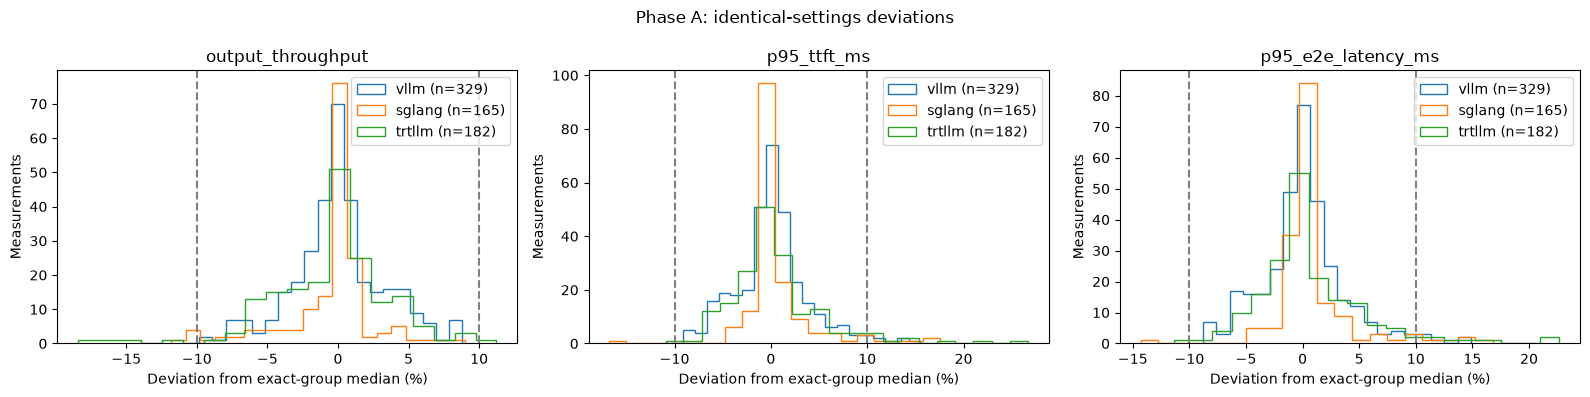

Nearby numeric settings: median differences mix parameter effects and measurement variation.
vllm


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
217,p95_ttft_ms,128,20c1786aee6e968543d0521075b72f51ed88519c9580cc653429a807015f5311,5e78a41791008a857b27bfe8797e7cb59d4efa5ae81852fa18bd1e957c662398,3,1,5620.949882,3090.172374,5603.307861,5669.813288,3090.172374,3090.172374,58.104511,"[{'parameter': 'max_num_seqs', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolerance': 8}]"
216,output_throughput,128,20c1786aee6e968543d0521075b72f51ed88519c9580cc653429a807015f5311,5e78a41791008a857b27bfe8797e7cb59d4efa5ae81852fa18bd1e957c662398,3,1,2820.821907,4978.660782,2770.697119,2838.979167,4978.660782,4978.660782,55.332872,"[{'parameter': 'max_num_seqs', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolerance': 8}]"
172,p95_ttft_ms,128,0e3dfa1b2735af7539d0c52c74bf3d2d992bd6a93440258bc98c66f4aaa7233a,6e5c16330a9782d3a575db73a3694f2e8f5c4e5df9bd44e21741f1df8e5fcdbc,3,3,3168.558579,5551.200313,3110.848066,3179.302432,5448.276986,5748.213597,54.649257,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
218,p95_e2e_latency_ms,128,20c1786aee6e968543d0521075b72f51ed88519c9580cc653429a807015f5311,5e78a41791008a857b27bfe8797e7cb59d4efa5ae81852fa18bd1e957c662398,3,1,5948.940460,3454.642807,5925.413401,5983.551131,3454.642807,3454.642807,53.049940,"[{'parameter': 'max_num_seqs', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolerance': 8}]"
171,output_throughput,128,0e3dfa1b2735af7539d0c52c74bf3d2d992bd6a93440258bc98c66f4aaa7233a,6e5c16330a9782d3a575db73a3694f2e8f5c4e5df9bd44e21741f1df8e5fcdbc,3,3,4830.058602,2839.186632,4771.418093,4962.511273,2757.124688,2874.240191,51.918329,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
220,p95_ttft_ms,128,e076f850de82b935e7bd786ccea6d70c0fcd06a52f4a965cc52b6f614d90d6dd,f93dfa43d2852ea6cc277d8bed4fb78ba1f2164de5a297a4c4beadbf7f4b92c4,2,2,3337.006457,5643.958036,3214.943578,3459.069337,5288.598929,5999.317143,51.374250,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
173,p95_e2e_latency_ms,128,0e3dfa1b2735af7539d0c52c74bf3d2d992bd6a93440258bc98c66f4aaa7233a,6e5c16330a9782d3a575db73a3694f2e8f5c4e5df9bd44e21741f1df8e5fcdbc,3,3,3553.722547,5860.267915,3482.789742,3554.470754,5767.716760,6074.907139,49.002501,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
219,output_throughput,128,e076f850de82b935e7bd786ccea6d70c0fcd06a52f4a965cc52b6f614d90d6dd,f93dfa43d2852ea6cc277d8bed4fb78ba1f2164de5a297a4c4beadbf7f4b92c4,2,2,4482.019893,2798.836243,4355.949873,4608.089912,2656.908837,2940.763649,46.235872,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
221,p95_e2e_latency_ms,128,e076f850de82b935e7bd786ccea6d70c0fcd06a52f4a965cc52b6f614d90d6dd,f93dfa43d2852ea6cc277d8bed4fb78ba1f2164de5a297a4c4beadbf7f4b92c4,2,2,3739.133568,5974.185462,3606.386409,3871.880728,5603.796847,6344.574076,46.020354,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolerance': 8}]"
204,output_throughput,128,e10e688517af49ee65974764f2a8d02332eda217ace3d3b320df86e95b6c6f5b,49fe294de52757b22131dd5521e8419f65e75a14fa4195ee95b99e5a83730ac0,3,1,4623.960787,6678.216919,4581.680797,4773.297312,6678.216919,6678.216919,36.351510,"[{'parameter': 'max_num_seqs', 'left': 16, 'right': 24, 'absolute_difference': 8, 'tolerance': 8}]"


sglang


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
490,p95_ttft_ms,128,81dab1ca4e64547ed2daab1f25b913bb6d512452fb795cef06a8ea62b2c0a05f,85b8948278fb4d0643332beb3e4d6cc28a10483d43416a23af852b389ca403ee,3,1,1912.026214,6541.769858,1903.683916,2247.479367,6541.769858,6541.769858,109.530526,"[{'parameter': 'max_running_requests', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolera..."
491,p95_e2e_latency_ms,128,81dab1ca4e64547ed2daab1f25b913bb6d512452fb795cef06a8ea62b2c0a05f,85b8948278fb4d0643332beb3e4d6cc28a10483d43416a23af852b389ca403ee,3,1,2132.741402,6765.397263,2123.638250,2491.073990,6765.397263,6765.397263,104.126403,"[{'parameter': 'max_running_requests', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolera..."
484,p95_ttft_ms,128,db4c437619bf502f43fbb4db808e341f8e1d9d70cf91c7e719eef25e9abcb6f3,34eb7c4a007128049cb05743489de3b07cb87ffe3bf255d15da8d5d83ed0aa6d,1,3,5962.486750,1884.240097,5962.486750,5962.486750,1883.284702,1897.939801,103.947716,"[{'parameter': 'max_running_requests', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolera..."
376,p95_ttft_ms,128,2f6382029e71c91a356be86e31e7ba397b759e66846b2e2defaa5955bf3c3d80,c08e36c548429cf83b437c4f0698e38cfeeab573dbfe9ee27760924e7f0b3a9f,3,1,5932.357434,1959.350386,5867.864385,6385.898715,1959.350386,1959.350386,100.688144,"[{'parameter': 'max_running_requests', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolera..."
241,p95_ttft_ms,128,9a6e0317a8ba55746f83e8eb0d36ac83f9ec099f394820c8ea443e05681910eb,256253dd13ca023f3bbced3f5654f08234d43757eb4dab4d4621c7c88f978039,6,1,1550.908095,4684.470069,1540.448522,1657.764354,4684.470069,4684.470069,100.509124,"[{'parameter': 'max_running_requests', 'left': 24, 'right': 16, 'absolute_difference': 8, 'toler..."
586,p95_ttft_ms,128,0446776ae0abd563de5c5b50d77b691531c6d1674e7c192ac1f190957ce2c5d6,32454fad31c583e7d73cea92499169dda8a9945153ce467483c8814389ed5824,1,3,5849.694294,1944.541800,5849.694294,5849.694294,1895.285411,1985.110765,100.206164,"[{'parameter': 'max_running_requests', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolera..."
442,p95_ttft_ms,128,366f8854f270b284ef2829c2694cfdeaf24969a6fc91f843aa0f3ad1a83bccbd,e05fc0774996e67df3f9d0c3c97327dce7cc30f87a82d7bcfdad052654020d3e,3,1,2252.462783,6714.436606,2226.587756,2301.492378,6714.436606,6714.436606,99.520997,"[{'parameter': 'max_running_requests', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolera..."
485,p95_e2e_latency_ms,128,db4c437619bf502f43fbb4db808e341f8e1d9d70cf91c7e719eef25e9abcb6f3,34eb7c4a007128049cb05743489de3b07cb87ffe3bf255d15da8d5d83ed0aa6d,1,3,6165.076464,2103.992621,6165.076464,6165.076464,2100.042197,2116.810456,98.223483,"[{'parameter': 'max_running_requests', 'left': 8, 'right': 16, 'absolute_difference': 8, 'tolera..."
418,p95_ttft_ms,128,32d88ab345a8d1be52a3d2be3d55b2715ac54dd8f70c866385e83cbc957ded97,82270d96a48ab0e8b6ca26c04d43a2ee169dc7ae36edf7747d7028839bf0ee99,4,1,1541.144893,4465.533987,1538.035001,1612.569279,4465.533987,4465.533987,97.371248,"[{'parameter': 'chunked_prefill_size', 'left': 6144, 'right': 4096, 'absolute_difference': 2048,..."
443,p95_e2e_latency_ms,128,366f8854f270b284ef2829c2694cfdeaf24969a6fc91f843aa0f3ad1a83bccbd,e05fc0774996e67df3f9d0c3c97327dce7cc30f87a82d7bcfdad052654020d3e,3,1,2476.490217,6962.393445,2452.259027,2529.333816,6962.393445,6962.393445,95.051563,"[{'parameter': 'max_running_requests', 'left': 16, 'right': 8, 'absolute_difference': 8, 'tolera..."


trtllm


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
675,output_throughput,128,3b7cff4ca21bdfdf47291ada682305097e0b68bba372a30b00b92b35f41ee23f,1a3aa904039f687b3b166a379de7651cd81796b1fb36866bf1b69e1558009d79,1,2,8403.579291,5875.581186,8403.579291,8403.579291,5871.381221,5879.781151,35.408218,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 2048, 'absolute_difference': 2048, 'tole..."
677,p95_e2e_latency_ms,128,3b7cff4ca21bdfdf47291ada682305097e0b68bba372a30b00b92b35f41ee23f,1a3aa904039f687b3b166a379de7651cd81796b1fb36866bf1b69e1558009d79,1,2,2117.699326,2981.467975,2117.699326,2117.699326,2967.743795,2995.192155,33.878812,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 2048, 'absolute_difference': 2048, 'tole..."
676,p95_ttft_ms,128,3b7cff4ca21bdfdf47291ada682305097e0b68bba372a30b00b92b35f41ee23f,1a3aa904039f687b3b166a379de7651cd81796b1fb36866bf1b69e1558009d79,1,2,1721.161075,2373.383242,1721.161075,1721.161075,2365.498339,2381.268145,31.858108,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 2048, 'absolute_difference': 2048, 'tole..."
712,p95_ttft_ms,128,06adbd2bf5cc313a2134afba595d7553120f3529647a45886a0e18a90c3d5b0e,e90669aabea4179049c4bfd26bbb32c10105615571c0655b9dc41079309d3e64,1,1,2807.839643,2215.814637,2807.839643,2807.839643,2215.814637,2215.814637,23.569496,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
713,p95_e2e_latency_ms,128,06adbd2bf5cc313a2134afba595d7553120f3529647a45886a0e18a90c3d5b0e,e90669aabea4179049c4bfd26bbb32c10105615571c0655b9dc41079309d3e64,1,1,3096.888422,2455.662052,3096.888422,3096.888422,2455.662052,2455.662052,23.096643,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
711,output_throughput,128,06adbd2bf5cc313a2134afba595d7553120f3529647a45886a0e18a90c3d5b0e,e90669aabea4179049c4bfd26bbb32c10105615571c0655b9dc41079309d3e64,1,1,5481.182777,6602.605665,5481.182777,5481.182777,6602.605665,6602.605665,18.560783,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
666,output_throughput,128,2cb93aec90695ff7c8608711bd1bd416f19bb60c4a8943cadfdd073016629604,cdda73b3dd757c7b03df74f023d1f91fbc4b79eb7427f4416acb4e17d5e0ccb3,6,3,7932.516787,9435.466178,7325.734063,8399.781503,9154.897065,9635.181631,17.307126,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 6144, 'absolute_difference': 2048, 'tole..."
668,p95_e2e_latency_ms,128,2cb93aec90695ff7c8608711bd1bd416f19bb60c4a8943cadfdd073016629604,cdda73b3dd757c7b03df74f023d1f91fbc4b79eb7427f4416acb4e17d5e0ccb3,6,3,2205.702118,1880.415443,2112.952345,2443.720611,1828.386538,1919.316437,15.921552,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 6144, 'absolute_difference': 2048, 'tole..."
667,p95_ttft_ms,128,2cb93aec90695ff7c8608711bd1bd416f19bb60c4a8943cadfdd073016629604,cdda73b3dd757c7b03df74f023d1f91fbc4b79eb7427f4416acb4e17d5e0ccb3,6,3,1785.282109,1539.626916,1714.627802,1990.025894,1492.638574,1570.692609,14.776657,"[{'parameter': 'max_num_tokens', 'left': 4096, 'right': 6144, 'absolute_difference': 2048, 'tole..."
669,output_throughput,128,59b6e08945c81ce4be333cd8be35d0c16291d2d3aa4e93c1162f64c81ddf020e,3b7cff4ca21bdfdf47291ada682305097e0b68bba372a30b00b92b35f41ee23f,6,1,9641.476161,8403.579291,9496.081393,10005.605331,8403.579291,8403.579291,13.720067,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 4096, 'absolute_difference': 2048, 'tole..."


In [6]:
show_phase("A")


## Phase B

Exact repetitions and nearby-setting comparisons for the Phase B model and workloads only. Results are not pooled with Phase A.


,framework,valid_measurements,exact_configs,repeated_configs,measurements_in_repeated_configs,singleton_configs
0,vllm,144,75,12,81,63
1,sglang,164,67,18,115,49
2,trtllm,132,64,17,85,47


trial_state,COMPLETE,FAIL,RUNNING,WAITING
framework,,,,
sglang,164,143,0,0
trtllm,132,23,1,0
vllm,144,0,1,4


Range of observed deviations, by framework and metric:


,framework,metric,observations,median,p90,p95,maximum
0,sglang,output_throughput,115,0.297285,2.353052,4.617615,12.619297
1,sglang,p95_e2e_latency_ms,115,0.356734,3.272022,7.069495,21.410214
2,sglang,p95_ttft_ms,115,0.402074,3.339390,7.603391,21.782307
3,trtllm,output_throughput,85,0.533457,5.354321,6.113883,11.647559
4,trtllm,p95_e2e_latency_ms,85,0.531497,4.537438,6.225455,10.551133
5,trtllm,p95_ttft_ms,85,0.592963,5.195949,6.818023,10.611568
6,vllm,output_throughput,81,1.239034,4.728683,5.929040,8.003805
7,vllm,p95_e2e_latency_ms,81,1.512501,5.179086,6.755084,8.813489
8,vllm,p95_ttft_ms,81,1.374014,4.634574,6.378831,8.177401


These percentiles describe saved observations; heavily repeated configs contribute more points.
vllm: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
488,311b9c4dcb02d0b54f751b547f607e4d3c6f170db96fdeadefc75c313a43297e,128,p95_e2e_latency_ms,8,4638.592934,5444.507538,5086.928866,15.842852,4.768530,8.813489,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 88, 'max_num_batched_tokens': 1536, 'gpu_memory_utilization': 0.75, 'enable_chu..."
487,311b9c4dcb02d0b54f751b547f607e4d3c6f170db96fdeadefc75c313a43297e,128,p95_ttft_ms,8,1932.247189,2267.084415,2095.709827,15.977270,4.692701,8.177401,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 88, 'max_num_batched_tokens': 1536, 'gpu_memory_utilization': 0.75, 'enable_chu..."
486,311b9c4dcb02d0b54f751b547f607e4d3c6f170db96fdeadefc75c313a43297e,128,output_throughput,8,3536.150604,3932.236140,3640.831105,10.878987,4.036728,8.003805,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 88, 'max_num_batched_tokens': 1536, 'gpu_memory_utilization': 0.75, 'enable_chu..."
491,93410531983c401a0d862fc1067685db80804e2e7d0b274f83507dcb81f95505,128,p95_e2e_latency_ms,8,3418.793622,3817.679914,3543.513113,11.256803,3.490222,7.737147,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 128, 'max_num_batched_tokens': 32512, 'gpu_memory_utilization': 0.8, 'enable_ch..."
489,93410531983c401a0d862fc1067685db80804e2e7d0b274f83507dcb81f95505,128,output_throughput,8,4662.820280,5207.313813,4849.728768,11.227299,3.217197,7.373300,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 128, 'max_num_batched_tokens': 32512, 'gpu_memory_utilization': 0.8, 'enable_ch..."
485,7eff7fa9d5325299428f418f6963360d3e2574cb38532ac95f8540934b4c304b,128,p95_e2e_latency_ms,8,5213.142094,6004.802017,5624.839405,14.074356,5.050284,7.319272,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 72, 'max_num_batched_tokens': 16896, 'gpu_memory_utilization': 0.85, 'enable_ch..."
484,7eff7fa9d5325299428f418f6963360d3e2574cb38532ac95f8540934b4c304b,128,p95_ttft_ms,8,2875.737982,3296.302196,3071.674950,13.691690,5.324311,7.312859,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 72, 'max_num_batched_tokens': 16896, 'gpu_memory_utilization': 0.85, 'enable_ch..."
494,9eb52d4043160fa8267b73872ebdccc639aa646a9e9c4fb1c722f24a803a424d,128,p95_e2e_latency_ms,8,5254.604063,5917.560321,5626.175823,11.783426,3.705774,6.604340,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 56, 'max_num_batched_tokens': 24320, 'gpu_memory_utilization': 0.75, 'enable_ch..."
492,9eb52d4043160fa8267b73872ebdccc639aa646a9e9c4fb1c722f24a803a424d,128,output_throughput,8,3646.382540,4066.238944,3822.120128,10.984909,3.489801,6.387000,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 56, 'max_num_batched_tokens': 24320, 'gpu_memory_utilization': 0.75, 'enable_ch..."
483,7eff7fa9d5325299428f418f6963360d3e2574cb38532ac95f8540934b4c304b,128,output_throughput,8,3115.766592,3481.083112,3277.221980,11.147140,4.175985,6.220547,False,"[B-vllm-c128-pareto_throughput-gp-s11-r3, B-vllm-c128-pareto_throughput-nsga2-s11-r3, B-vllm-c12...","{'max_num_seqs': 72, 'max_num_batched_tokens': 16896, 'gpu_memory_utilization': 0.85, 'enable_ch..."


sglang: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
382,a9f4c6a2eaa759a3268bb831d1de5170954ace5fcbf785f3687ab7093bdc0d40,128,p95_ttft_ms,9,40052.833016,49607.500193,40734.571021,23.455917,8.611058,21.782307,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 8, 'chunked_prefill_size': 4096, 'mem_fraction_static': 0.7, 'cuda_grap..."
383,a9f4c6a2eaa759a3268bb831d1de5170954ace5fcbf785f3687ab7093bdc0d40,128,p95_e2e_latency_ms,9,42612.044006,52617.399392,43338.527819,23.086514,8.468956,21.410214,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 8, 'chunked_prefill_size': 4096, 'mem_fraction_static': 0.7, 'cuda_grap..."
406,ffe09e120e9f5562f0033119f8b6041a087f7a60c42bc0fd3be5569eb46e8e9c,128,p95_ttft_ms,8,21936.977930,27124.994634,22407.568263,23.152966,8.928626,21.052826,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 16, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'cuda_gr..."
407,ffe09e120e9f5562f0033119f8b6041a087f7a60c42bc0fd3be5569eb46e8e9c,128,p95_e2e_latency_ms,8,24596.378214,30240.618704,25125.603343,22.464099,8.838335,20.357781,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 16, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'cuda_gr..."
405,ffe09e120e9f5562f0033119f8b6041a087f7a60c42bc0fd3be5569eb46e8e9c,128,output_throughput,8,588.460399,689.706383,673.444337,15.034054,6.333875,12.619297,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 16, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.75, 'cuda_gr..."
380,5e59335aa5c289ce8793ecd84fb9b68cdde1faa0a0aa3a63708a32f0c411242c,128,p95_e2e_latency_ms,10,22169.538041,24787.050349,22400.820621,11.684895,3.429813,10.652421,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 24, 'chunked_prefill_size': 6144, 'mem_fraction_static': 0.8, 'cuda_gra..."
379,5e59335aa5c289ce8793ecd84fb9b68cdde1faa0a0aa3a63708a32f0c411242c,128,p95_ttft_ms,10,19488.396471,21736.027480,19710.253285,11.403359,3.336952,10.277768,True,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 24, 'chunked_prefill_size': 6144, 'mem_fraction_static': 0.8, 'cuda_gra..."
381,a9f4c6a2eaa759a3268bb831d1de5170954ace5fcbf785f3687ab7093bdc0d40,128,output_throughput,9,339.377439,382.681722,376.042103,11.515807,4.381702,9.750149,False,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 8, 'chunked_prefill_size': 4096, 'mem_fraction_static': 0.7, 'cuda_grap..."
388,cc9da7559e8360ad9464c085d84ee3e2c3934e547e6348b0d46c453e0a32e6db,128,p95_ttft_ms,9,20220.432422,22245.260588,20394.539733,9.928286,3.311309,9.074590,False,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.85, 'cuda_gra..."
389,cc9da7559e8360ad9464c085d84ee3e2c3934e547e6348b0d46c453e0a32e6db,128,p95_e2e_latency_ms,9,20986.851835,23056.278298,21152.483765,9.783373,3.267039,9.000336,False,"[B-sglang-c128-e2e-gp-s11-r1, B-sglang-c128-e2e-tpe_multivariate-s11-r1, B-sglang-c128-pareto_th...","{'max_running_requests': 8, 'chunked_prefill_size': 2048, 'mem_fraction_static': 0.85, 'cuda_gra..."


trtllm: largest exact-settings variation (inspect repeat counts and metadata).


,exact_group_id,concurrency,metric,n,min,max,median,spread_pct,cv_pct,max_abs_deviation_pct,alert,studies,server_config
450,cf899eb72f5f4673e5e15d3ed228c3d87383f267c40bfec69f8134969ae3db57,128,output_throughput,7,261.002545,312.160484,295.410677,17.317566,6.437695,11.647559,True,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 8, 'max_num_tokens': 8192, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_c..."
451,cf899eb72f5f4673e5e15d3ed228c3d87383f267c40bfec69f8134969ae3db57,128,p95_ttft_ms,7,49886.456838,58780.992602,53141.812888,16.737359,5.828777,10.611568,True,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 8, 'max_num_tokens': 8192, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_c..."
452,cf899eb72f5f4673e5e15d3ed228c3d87383f267c40bfec69f8134969ae3db57,128,p95_e2e_latency_ms,7,53090.621777,62596.621676,56622.324801,16.788431,5.860107,10.551133,True,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 8, 'max_num_tokens': 8192, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_c..."
441,dcbbd8aa144d38f39d4b00d39a0036d6f897d892ffdcd537890a7cf88bc0a5dd,128,output_throughput,7,863.408486,1026.957322,958.932977,17.055294,6.162098,9.961540,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 2048, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
443,dcbbd8aa144d38f39d4b00d39a0036d6f897d892ffdcd537890a7cf88bc0a5dd,128,p95_e2e_latency_ms,7,18923.345533,21787.997209,19870.524172,14.416588,5.203910,9.649836,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 2048, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
454,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,128,p95_ttft_ms,6,15662.057679,17222.328249,15915.724464,9.803327,4.097334,8.209515,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 6144, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
455,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,128,p95_e2e_latency_ms,6,19075.869872,21065.758414,19494.243509,10.207570,4.320875,8.061431,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 6144, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
442,dcbbd8aa144d38f39d4b00d39a0036d6f897d892ffdcd537890a7cf88bc0a5dd,128,p95_ttft_ms,7,15561.882472,17515.867621,16236.102988,12.034816,4.708663,7.882216,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 2048, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
448,f4ec6ac138a10d1e753b6bed18f0c141c8207b65272b6925fdae8feaf22c5ae4,128,p95_ttft_ms,12,3018.006206,3241.668565,3032.279050,7.376048,2.582151,6.905351,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 8192, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."
453,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,128,output_throughput,6,950.981866,1050.076515,1013.649979,9.776022,4.356309,6.182421,False,"[B-trtllm-c128-e2e-gp-s11-r2, B-trtllm-c128-e2e-tpe_multivariate-s11-r2, B-trtllm-c128-pareto_th...","{'max_batch_size': 32, 'max_num_tokens': 6144, 'config': {'attn_backend': 'TRTLLM', 'cuda_graph_..."


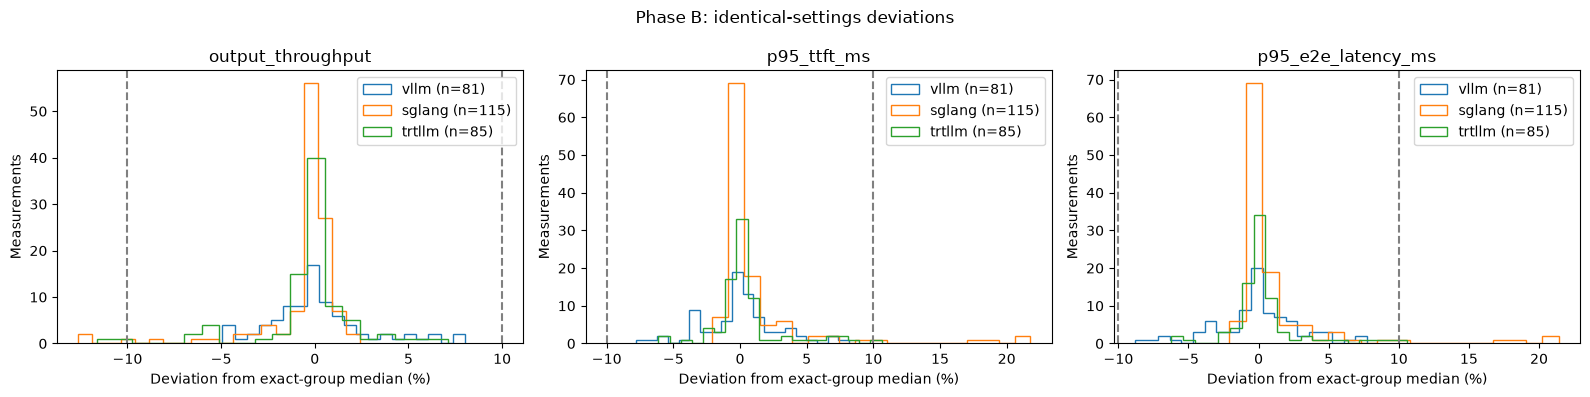

Nearby numeric settings: median differences mix parameter effects and measurement variation.
vllm


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
741,output_throughput,128,fb00698491ab45565a9ae5e9eb0e2c505ab6bb98a3458d0bada7ae013bca230b,880fd604ed438cfcc1ecb757e97a316522ac9e444e175509d58f799e6d9bc62a,1,1,4912.272780,3550.586871,4912.272780,4912.272780,3550.586871,3550.586871,32.180279,"[{'parameter': 'max_num_batched_tokens', 'left': 1792, 'right': 1024, 'absolute_difference': 768..."
743,p95_e2e_latency_ms,128,fb00698491ab45565a9ae5e9eb0e2c505ab6bb98a3458d0bada7ae013bca230b,880fd604ed438cfcc1ecb757e97a316522ac9e444e175509d58f799e6d9bc62a,1,1,3750.450427,5135.922328,3750.450427,3750.450427,5135.922328,5135.922328,31.181944,"[{'parameter': 'max_num_batched_tokens', 'left': 1792, 'right': 1024, 'absolute_difference': 768..."
742,p95_ttft_ms,128,fb00698491ab45565a9ae5e9eb0e2c505ab6bb98a3458d0bada7ae013bca230b,880fd604ed438cfcc1ecb757e97a316522ac9e444e175509d58f799e6d9bc62a,1,1,2041.755025,2699.727565,2041.755025,2041.755025,2699.727565,2699.727565,27.753874,"[{'parameter': 'max_num_batched_tokens', 'left': 1792, 'right': 1024, 'absolute_difference': 768..."
736,p95_ttft_ms,128,1e1fd2b43699c60115e65a3987eec2beb6c19c4edf5aec2f161022d9fb8f2b07,8652b4c120804bd515805cb7025c40fcad1cb44568a3ff33d334b58220f04d52,1,1,1679.026476,1565.254093,1679.026476,1679.026476,1565.254093,1565.254093,7.013720,"[{'parameter': 'max_num_batched_tokens', 'left': 8704, 'right': 6656, 'absolute_difference': 204..."
739,p95_ttft_ms,128,e1860e50f49ad90fd75906daabc552c95f433296ccdd77081bce03fae659396f,a1870dda674eab38068417cda098acdef8f0be88eb227dbe0d11a44bed5b099a,1,1,1634.573929,1603.189626,1634.573929,1634.573929,1603.189626,1603.189626,1.938641,"[{'parameter': 'max_num_batched_tokens', 'left': 6912, 'right': 7424, 'absolute_difference': 512..."
737,p95_e2e_latency_ms,128,1e1fd2b43699c60115e65a3987eec2beb6c19c4edf5aec2f161022d9fb8f2b07,8652b4c120804bd515805cb7025c40fcad1cb44568a3ff33d334b58220f04d52,1,1,3411.879323,3401.427210,3411.879323,3411.879323,3401.427210,3401.427210,0.306815,"[{'parameter': 'max_num_batched_tokens', 'left': 8704, 'right': 6656, 'absolute_difference': 204..."
740,p95_e2e_latency_ms,128,e1860e50f49ad90fd75906daabc552c95f433296ccdd77081bce03fae659396f,a1870dda674eab38068417cda098acdef8f0be88eb227dbe0d11a44bed5b099a,1,1,3301.486214,3299.040544,3301.486214,3301.486214,3299.040544,3299.040544,0.074105,"[{'parameter': 'max_num_batched_tokens', 'left': 6912, 'right': 7424, 'absolute_difference': 512..."
735,output_throughput,128,1e1fd2b43699c60115e65a3987eec2beb6c19c4edf5aec2f161022d9fb8f2b07,8652b4c120804bd515805cb7025c40fcad1cb44568a3ff33d334b58220f04d52,1,1,6736.817148,6733.924734,6736.817148,6736.817148,6733.924734,6733.924734,0.042944,"[{'parameter': 'max_num_batched_tokens', 'left': 8704, 'right': 6656, 'absolute_difference': 204..."
738,output_throughput,128,e1860e50f49ad90fd75906daabc552c95f433296ccdd77081bce03fae659396f,a1870dda674eab38068417cda098acdef8f0be88eb227dbe0d11a44bed5b099a,1,1,6551.410445,6553.758814,6551.410445,6551.410445,6553.758814,6553.758814,0.035839,"[{'parameter': 'max_num_batched_tokens', 'left': 6912, 'right': 7424, 'absolute_difference': 512..."


sglang


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
719,p95_e2e_latency_ms,128,7436f6e57c1a75e20fdbade18e2ec3986a20b9d1f76bef985746a27a340b9e0e,40cea45c6c0a159c9fb676b7f8a6c711e8a45aec5fb402ae649e3ddd6289b2e0,5,1,5381.909426,5441.157441,5361.893128,5525.319446,5441.157441,5441.157441,1.094847,"[{'parameter': 'chunked_prefill_size', 'left': 8192, 'right': 6144, 'absolute_difference': 2048,..."
718,p95_ttft_ms,128,7436f6e57c1a75e20fdbade18e2ec3986a20b9d1f76bef985746a27a340b9e0e,40cea45c6c0a159c9fb676b7f8a6c711e8a45aec5fb402ae649e3ddd6289b2e0,5,1,4662.516869,4709.540032,4642.906479,4806.127131,4709.540032,4709.540032,1.003476,"[{'parameter': 'chunked_prefill_size', 'left': 8192, 'right': 6144, 'absolute_difference': 2048,..."
715,p95_ttft_ms,128,5cac120da6cf9f90e619bed983ebf98913700c0f3b106256c12673d210f7faec,879262a4545460d4fdea15c929952521156612c3fc78f1173e74201e1eac903a,14,1,4677.611572,4635.225908,4658.584418,4783.914224,4635.225908,4635.225908,0.910263,"[{'parameter': 'mem_fraction_static', 'left': 0.75, 'right': 0.8, 'absolute_difference': 0.05000..."
716,p95_e2e_latency_ms,128,5cac120da6cf9f90e619bed983ebf98913700c0f3b106256c12673d210f7faec,879262a4545460d4fdea15c929952521156612c3fc78f1173e74201e1eac903a,14,1,5407.339186,5365.730979,5385.575013,5515.299833,5365.730979,5365.730979,0.772448,"[{'parameter': 'mem_fraction_static', 'left': 0.75, 'right': 0.8, 'absolute_difference': 0.05000..."
717,output_throughput,128,7436f6e57c1a75e20fdbade18e2ec3986a20b9d1f76bef985746a27a340b9e0e,40cea45c6c0a159c9fb676b7f8a6c711e8a45aec5fb402ae649e3ddd6289b2e0,5,1,3858.011828,3829.877924,3837.714116,3860.953772,3829.877924,3829.877924,0.731902,"[{'parameter': 'chunked_prefill_size', 'left': 8192, 'right': 6144, 'absolute_difference': 2048,..."
714,output_throughput,128,5cac120da6cf9f90e619bed983ebf98913700c0f3b106256c12673d210f7faec,879262a4545460d4fdea15c929952521156612c3fc78f1173e74201e1eac903a,14,1,3845.533796,3851.938033,3829.185121,3851.183121,3851.938033,3851.938033,0.166398,"[{'parameter': 'mem_fraction_static', 'left': 0.75, 'right': 0.8, 'absolute_difference': 0.05000..."


trtllm


,metric,concurrency,left_group_id,right_group_id,left_n,right_n,left_median,right_median,left_min,left_max,right_min,right_max,median_gap_pct,parameter_changes
720,output_throughput,128,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,2fddd1c411b53e2206f9f30fe4220b9254c5c49d68208dbe610d50f6b3d5f2e6,6,1,1013.649979,855.949557,950.981866,1050.076515,855.949557,855.949557,16.869968,"[{'parameter': 'max_batch_size', 'left': 32, 'right': 24, 'absolute_difference': 8, 'tolerance':..."
721,p95_ttft_ms,128,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,2fddd1c411b53e2206f9f30fe4220b9254c5c49d68208dbe610d50f6b3d5f2e6,6,1,15915.724464,17071.726612,15662.057679,17222.328249,17071.726612,17071.726612,7.008739,"[{'parameter': 'max_batch_size', 'left': 32, 'right': 24, 'absolute_difference': 8, 'tolerance':..."
722,p95_e2e_latency_ms,128,9dc338f219e5bba74bf9f9a8106df1294ebe6a0cf9d16149bbbcb6a7ff8d01c2,2fddd1c411b53e2206f9f30fe4220b9254c5c49d68208dbe610d50f6b3d5f2e6,6,1,19494.243509,20341.250088,19075.869872,21065.758414,20341.250088,20341.250088,4.252522,"[{'parameter': 'max_batch_size', 'left': 32, 'right': 24, 'absolute_difference': 8, 'tolerance':..."
730,p95_ttft_ms,128,9a3b9fd35c74334413887e13b3149a94d882f25065642c18d5ac44d164f20b31,719443ed307d0d8474a8a8560a720794eb994286a34a963895de820bd0217139,1,2,2955.682043,3079.991003,2955.682043,2955.682043,3066.961644,3093.020363,4.119142,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
733,p95_ttft_ms,128,cac837b5623bf5bc6fd8a4089c68bfa5a8e1036dc746b2daaa8a9789b44b6ad7,3dac94c060c8d5eb68949edf6204ab3e0a11ec2fa03eac16a2d67fc4f2bdbc2f,1,1,2976.464539,3070.210142,2976.464539,2976.464539,3070.210142,3070.210142,3.100732,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
731,p95_e2e_latency_ms,128,9a3b9fd35c74334413887e13b3149a94d882f25065642c18d5ac44d164f20b31,719443ed307d0d8474a8a8560a720794eb994286a34a963895de820bd0217139,1,2,3752.892612,3866.212538,3752.892612,3752.892612,3855.709782,3876.715294,2.974626,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
728,p95_e2e_latency_ms,128,9a3b9fd35c74334413887e13b3149a94d882f25065642c18d5ac44d164f20b31,413ff78a14d190a47c95439e29aecac3e63b4ffe894d23b763a299ba80621c96,1,1,3752.892612,3857.274325,3752.892612,3752.892612,3857.274325,3857.274325,2.743217,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 4096, 'absolute_difference': 2048, 'tole..."
734,p95_e2e_latency_ms,128,cac837b5623bf5bc6fd8a4089c68bfa5a8e1036dc746b2daaa8a9789b44b6ad7,3dac94c060c8d5eb68949edf6204ab3e0a11ec2fa03eac16a2d67fc4f2bdbc2f,1,1,3772.662811,3845.327856,3772.662811,3772.662811,3845.327856,3845.327856,1.907722,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
732,output_throughput,128,cac837b5623bf5bc6fd8a4089c68bfa5a8e1036dc746b2daaa8a9789b44b6ad7,3dac94c060c8d5eb68949edf6204ab3e0a11ec2fa03eac16a2d67fc4f2bdbc2f,1,1,4330.635762,4260.372830,4330.635762,4330.635762,4260.372830,4260.372830,1.635732,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."
729,output_throughput,128,9a3b9fd35c74334413887e13b3149a94d882f25065642c18d5ac44d164f20b31,719443ed307d0d8474a8a8560a720794eb994286a34a963895de820bd0217139,1,2,4354.391286,4291.557687,4354.391286,4354.391286,4279.533152,4303.582223,1.453481,"[{'parameter': 'max_num_tokens', 'left': 6144, 'right': 8192, 'absolute_difference': 2048, 'tole..."


In [7]:
show_phase("B")


## Inspect an exact configuration

Select a group ID from either phase's tables. The default is the group with the largest observed absolute deviation. Inspect source lines, study/trial identity, settings, and all raw values before attributing a large difference to GPU variation. The timestamp comes from the matched SQLite trial; it includes server startup and benchmark execution.


Executed server settings:


{'max_batch_size': 24,
 'max_num_tokens': 6144,
 'config': {'cuda_graph_config': {'batch_sizes': [1, 2, 4, 8, 16, 24],
   'enable_padding': True},
  'kv_cache_config': {'free_gpu_memory_fraction': 0.85}}}

Identity limitations:


['model_revision missing or placeholder',
 'framework_version missing or placeholder',
 'cuda_version missing or placeholder',
 'driver_version missing or placeholder',
 'Physical GPU identity not recorded']

,phase,framework,concurrency,study_name,trial_number,sampler,datetime_start,output_throughput,p95_ttft_ms,p95_e2e_latency_ms,source_file,source_line
546,A,trtllm,128,A-trtllm-c128-e2e-tpe-s11-r1,0,tpe,2026-10-06 18:56:55.491951,6868.128935,2610.630769,2926.375132,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
549,A,trtllm,128,A-trtllm-c128-e2e-tpe-s11-r11,0,tpe,2026-10-06 19:17:28.837151,8140.371784,1916.193778,2220.549765,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
573,A,trtllm,128,A-trtllm-c128-e2e-tpe_multivariate-s11-r11,0,tpe_multivariate,2026-10-06 20:10:29.729212,7367.459310,2123.552130,2446.675554,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
522,A,trtllm,128,A-trtllm-c128-e2e-gp-s11-r11,0,gp,2026-10-06 20:48:48.328292,7086.394656,2225.902751,2570.519070,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
680,A,trtllm,128,A-trtllm-c128-throughput-tpe-s11-r1,0,tpe,2026-10-06 21:30:24.643966,7780.865691,1998.360928,2312.691078,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
703,A,trtllm,128,A-trtllm-c128-throughput-tpe_multivariate-s11-r1,0,tpe_multivariate,2026-10-06 22:05:33.487791,7291.072570,2061.162682,2379.973577,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1
671,A,trtllm,128,A-trtllm-c128-throughput-gp-s11-r1,0,gp,2026-10-06 22:42:20.987734,7318.893544,2057.341113,2385.897176,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/optuna-phase-b-v1/A-trtllm...,1


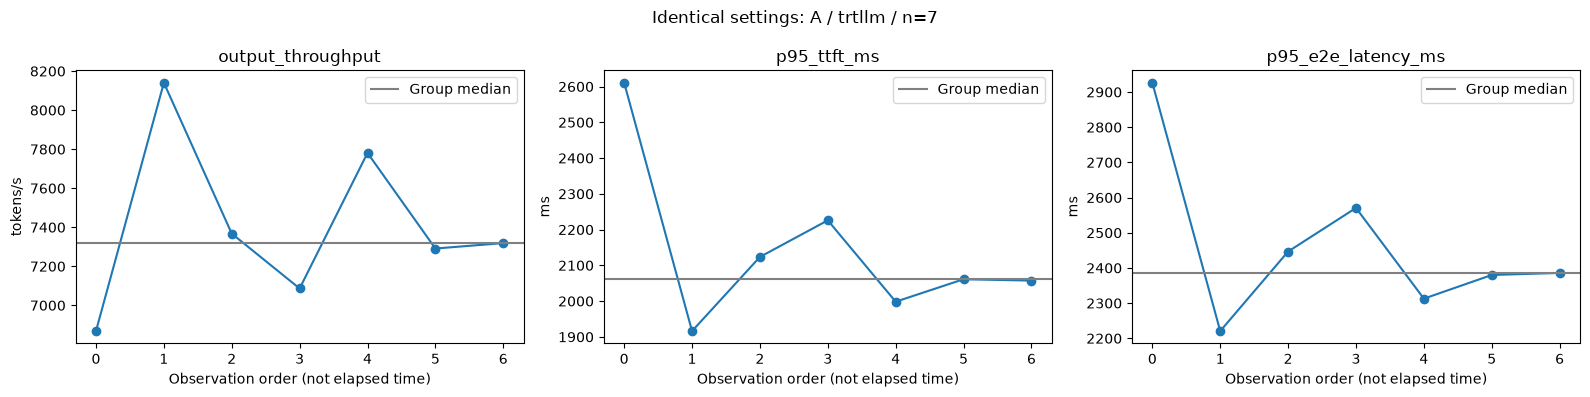

In [8]:
GROUP_ID = None  # Paste a full exact_group_id to choose another configuration.
if GROUP_ID is None and not repeat_metrics.empty:
    GROUP_ID = repeat_metrics.sort_values("max_abs_deviation_pct", ascending=False).iloc[0]["exact_group_id"]

if GROUP_ID:
    details = observations[observations["exact_group_id"] == GROUP_ID].sort_values(
        ["datetime_start", "study_name", "trial_number"], na_position="last"
    )
    if details.empty:
        print("No matching group in the selected observations.")
    else:
        print("Executed server settings:")
        display(details.iloc[0]["server_config"])
        print("Identity limitations:")
        display(details.iloc[0]["identity_warnings"])
        display(details[["phase", "framework", "concurrency", "study_name", "trial_number", "sampler",
                         "datetime_start", *METRICS, "source_file", "source_line"]])
        fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 4))
        for ax, metric in zip(axes, METRICS):
            values = details[metric].to_numpy()
            center = np.median(values)
            ax.plot(range(len(values)), values, marker="o")
            ax.axhline(center, color="gray", label="Group median")
            ax.set(title=metric, xlabel="Observation order (not elapsed time)", ylabel="tokens/s" if metric == "output_throughput" else "ms")
            ax.legend()
        fig.suptitle(f"Identical settings: {details.iloc[0]['phase']} / {details.iloc[0]['framework']} / n={len(details)}")
        fig.tight_layout()
        if SAVE_REPORT:
            REPORT_DIR.mkdir(parents=True, exist_ok=True)
            fig.savefig(REPORT_DIR / "selected-exact-group.png", dpi=180, bbox_inches="tight")
        plt.show()
else:
    print("No repeated configurations available for drill-down.")


## Save the analysis

Exports keep the raw observation references, exclusions, trial failures, identity warnings, exact ranges, and similar-parameter differences. Settings and comparison definitions are saved alongside the tables. Only the analysis directory is written; the source logs and studies stay unchanged.

These are historical checks, not independent reruns. A large exact-group range warrants controlled repeats with a pinned environment. Sparse groups or stable-looking pairs do not establish general GPU stability.


In [9]:
if SAVE_REPORT:
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    tables = {
        "observations": observations, "excluded_observations": excluded_observations,
        "trial_states": trials, "exact_groups": groups, "exact_metrics": repeat_metrics,
        "exact_deviations": deviations, "similar_pairs": neighbor_pairs,
        "identity_warnings": identity_warnings, "source_issues": pd.DataFrame(audit["issues"]),
    }
    for name, frame in tables.items():
        saved = frame.copy()
        for column in saved.select_dtypes(include="object").columns:
            saved[column] = saved[column].map(
                lambda value: json.dumps(value, sort_keys=True) if isinstance(value, (dict, list)) else value
            )
        saved.to_csv(REPORT_DIR / f"{name}.csv", index=False)
    manifest = {
        "run_dirs": [str(p.resolve()) for p in RUN_DIRS], "phases": PHASES, "frameworks": FRAMEWORKS,
        "min_repeats": MIN_REPEATS, "deviation_alert_pct": DEVIATION_ALERT_PCT,
        "numeric_tolerances": NUMERIC_TOLERANCES, "max_numeric_changes": MAX_NUMERIC_CHANGES,
        "include_unmatched": INCLUDE_UNMATCHED, "exclude_duplicate_records": EXCLUDE_DUPLICATE_RECORDS,
        "loaded_records": len(audit["records"]), "selected_records": len(selected), "excluded_records": len(excluded),
        "scope": "Historical GPU observations grouped by executed settings, workload fingerprints, and declared environment; neighboring settings include parameter effects.",
    }
    (REPORT_DIR / "analysis_settings.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print(f"Saved analysis to {REPORT_DIR}")
else:
    print("Report export disabled.")


/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in saved.select_dtypes(include="object").columns:


/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in saved.select_dtypes(include="object").columns:
/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select

/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in saved.select_dtypes(include="object").columns:


/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in saved.select_dtypes(include="object").columns:
/tmp/ipykernel_203514/3312949279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select

Saved analysis to /mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/phase_stability_analysis
